In [1]:
import os, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
warnings.filterwarnings("ignore")

In [2]:
import sys
print(sys.executable)

c:\Users\jhonm\OneDrive\Desktop\ComProg1\Lab8_Data_Visualization_Osorio\.venv\Scripts\python.exe


In [3]:
df = pd.read_csv(r"C:\Users\jhonm\OneDrive\Desktop\ComProg1\Lab8_Data_Visualization_Osorio\spotify_top_1000_tracks.csv")  
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year
print(df.columns.tolist())
print(df.head(3))

['track_name', 'artist', 'album', 'release_date', 'popularity', 'spotify_url', 'id', 'duration_min', 'year']
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9YMctZqd1...  7MXVkk9YMctZqd1Srtv4MB   
2  https://open.spotify.com/track/0TK2YIli7K1leLo...  0TK2YIli7K1leLovkQiNik   

   duration_min    year  
0      3.869767  2018.0  
1   

In [4]:
for c in ['track_name', 'artist', 'album']:
    df[c] = df[c].astype(str).str.strip()
df = df.dropna(subset=['year'])
df['year'] = df['year'].astype(int)
df = df.drop(columns=['spotify_url', 'id'], errors='ignore')   
df = df.drop_duplicates(subset=['track_name', 'artist'])
df['release_year'] = df['year']
df['decade'] = (df['year'] // 10) * 10
if 'tempo' in df.columns:
    df['tempo_category'] = pd.cut(df['tempo'], [0, 100, 140, np.inf],
                                  labels=['Slow', 'Medium', 'Fast'], right=False)
print("Rows:", len(df))

Rows: 951


In [5]:
student_name, student_id = "Your Name", "202512345"   # CHANGE
n = int(student_id[-3:])
color1 = f"#{(n*7)%256:02x}{(n*3)%256:02x}{(n*5)%256:02x}"
color2 = f"#{(n*2)%256:02x}{(n*9)%256:02x}{(n*4)%256:02x}"
T = f"{student_name} ({student_id})\n"
top3 = df['artist'].value_counts().head(3).index
print(color1, color2)

#6f0bbd #b22164


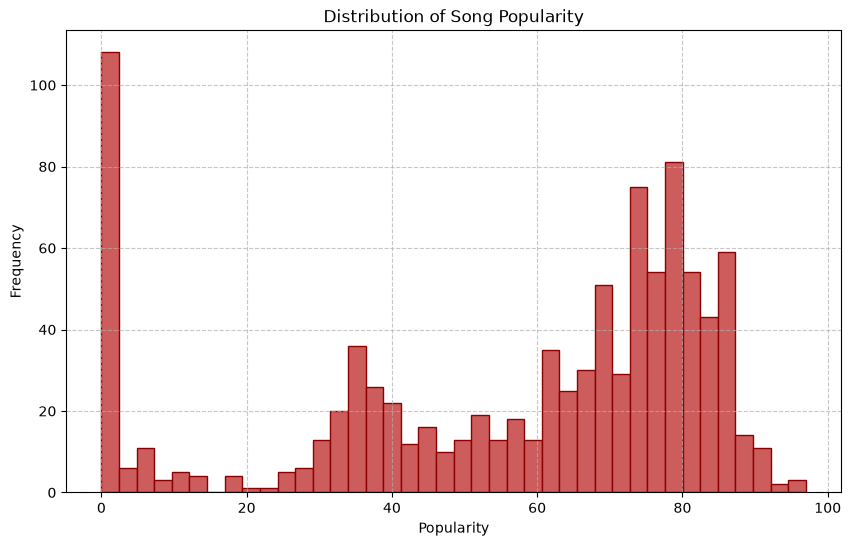

In [6]:
plt.figure(figsize=(10, 6))
plt.hist(df['popularity'], bins=40, color='indianred', edgecolor='darkred')
plt.title('Distribution of Song Popularity'); plt.xlabel('Popularity'); plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=.7); plt.show()

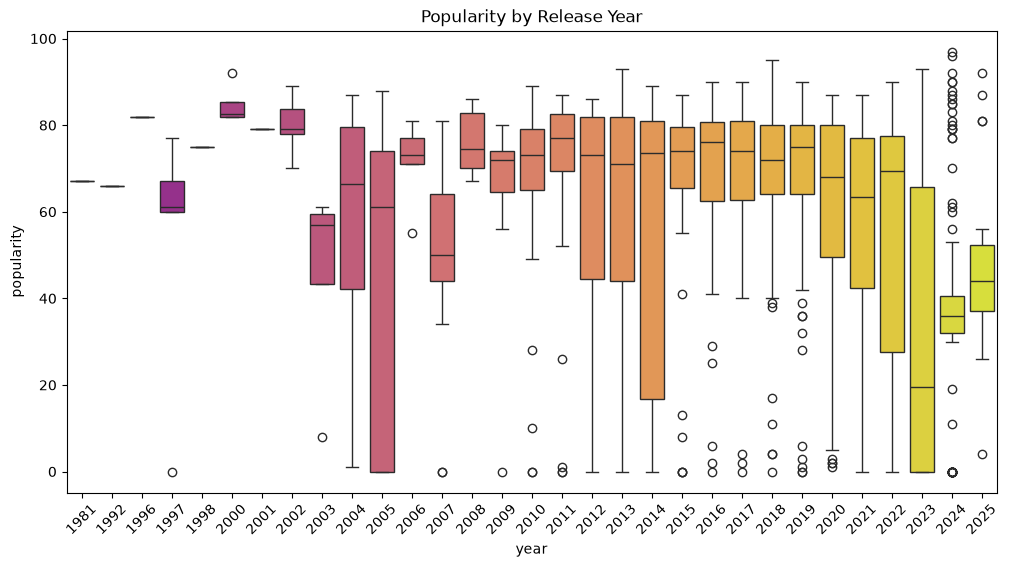

In [8]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df, hue='year', palette='plasma', legend=False)
plt.title('Popularity by Release Year'); plt.xticks(rotation=45); plt.show()

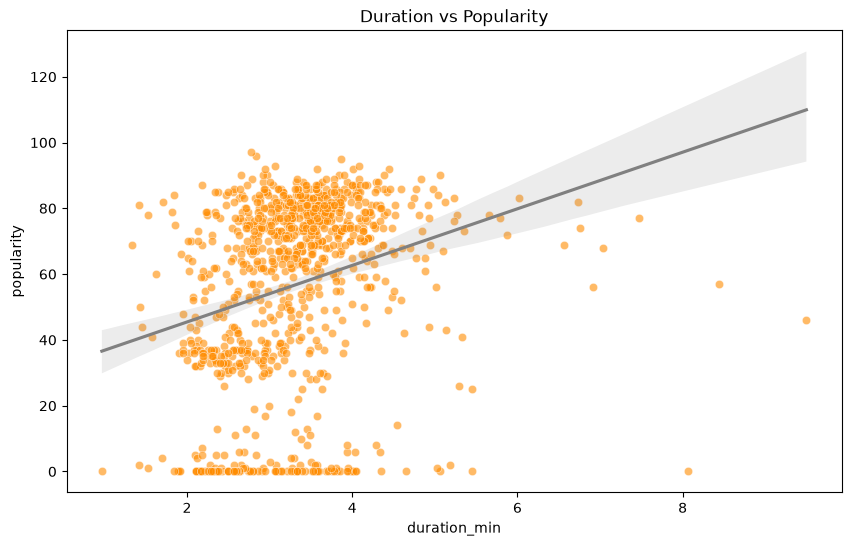

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='duration_min', y='popularity', data=df, alpha=.6, color='darkorange')
sns.regplot(x='duration_min', y='popularity', data=df, scatter=False, color='grey')
plt.title('Duration vs Popularity'); plt.show()

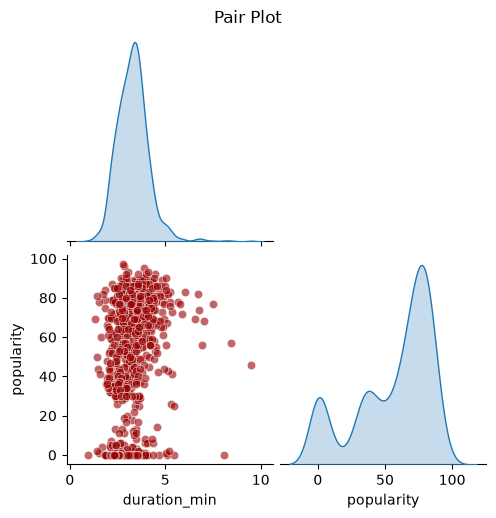

In [10]:
sns.pairplot(df[['duration_min', 'popularity']], diag_kind='kde', corner=True,
             plot_kws={'alpha': .6, 'color': '#990000'})
plt.suptitle('Pair Plot', y=1.02); plt.show()

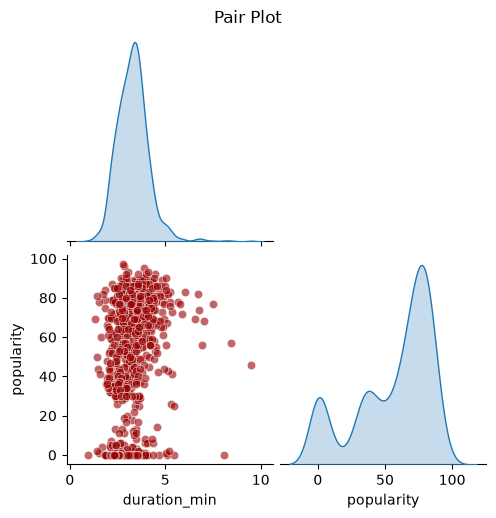

In [11]:
sns.pairplot(df[['duration_min', 'popularity']], diag_kind='kde', corner=True,
             plot_kws={'alpha': .6, 'color': '#990000'})
plt.suptitle('Pair Plot', y=1.02); plt.show()

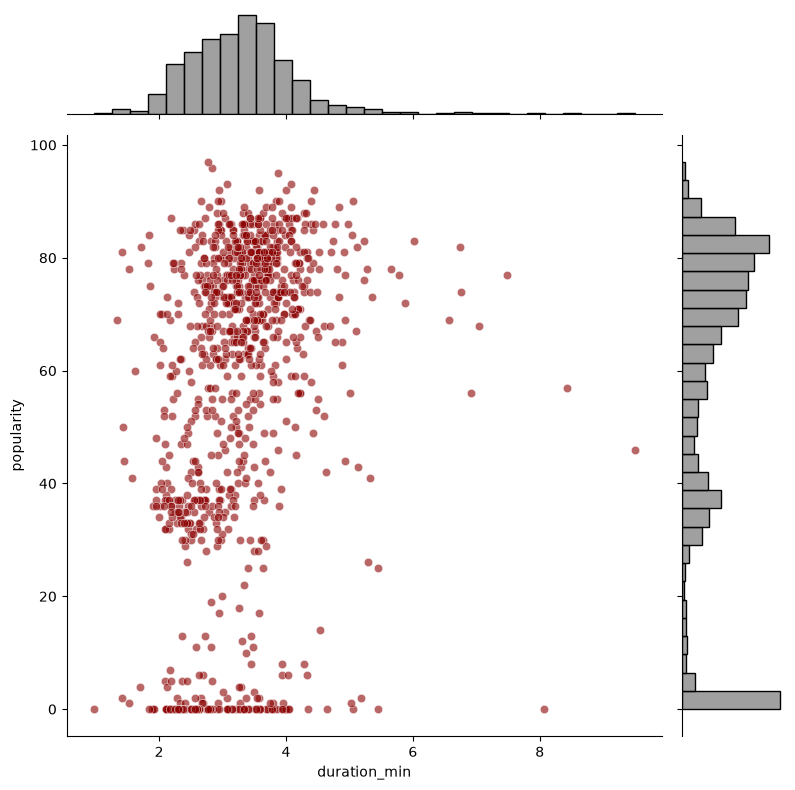

In [12]:
sns.jointplot(x='duration_min', y='popularity', data=df, kind='scatter', height=8,
              marginal_kws={'bins': 30, 'color': 'gray'}, joint_kws={'alpha': .6, 'color': 'darkred'})
plt.show()

In [13]:
yp = df.groupby('year')['popularity'].mean().reset_index().sort_values('year')
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(yp.year.min(), yp.year.max()); ax.set_ylim(0, yp.popularity.max() * 1.1)
line, = ax.plot([], [], color='royalblue', lw=2.5)
ax.set_title("Evolution of Track Popularity"); ax.set_xlabel("Year"); ax.set_ylabel("Avg Popularity")

def animate(i):
    line.set_data(yp.year[:i+1], yp.popularity[:i+1]); return line,

ani = FuncAnimation(fig, animate, frames=len(yp), interval=60, repeat=False)
ani.save("yearly_popularity_trend.gif", writer=PillowWriter(fps=10))
plt.close(fig); print("Saved:", os.path.abspath("yearly_popularity_trend.gif"))

Saved: c:\Users\jhonm\OneDrive\Desktop\ComProg1\Lab8_Data_Visualization_Osorio\yearly_popularity_trend.gif


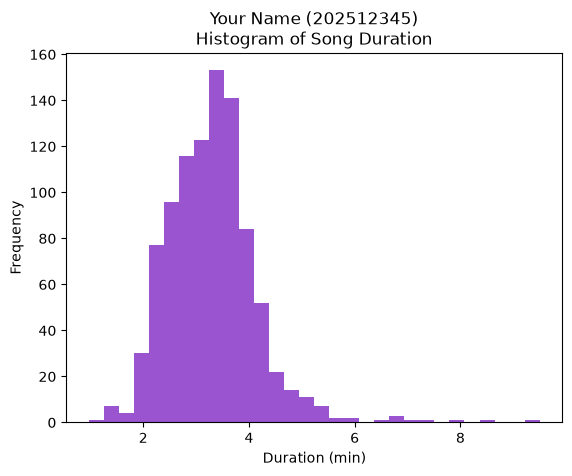

In [14]:
df['duration_min'].plot(kind='hist', bins=30, color=color1, alpha=.7)
plt.title(T+"Histogram of Song Duration"); plt.xlabel('Duration (min)'); plt.show()

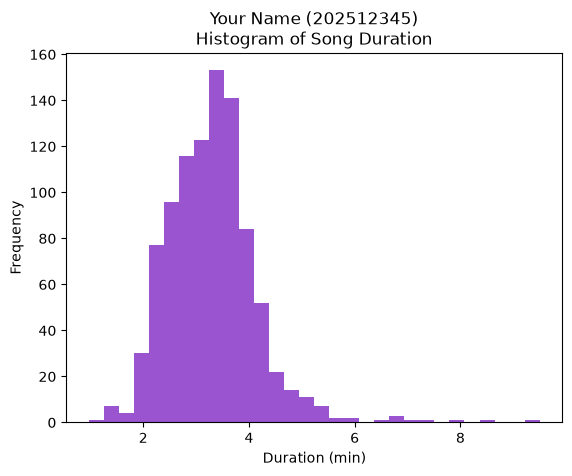

In [15]:
df['duration_min'].plot(kind='hist', bins=30, color=color1, alpha=.7)
plt.title(T+"Histogram of Song Duration"); plt.xlabel('Duration (min)'); plt.show()

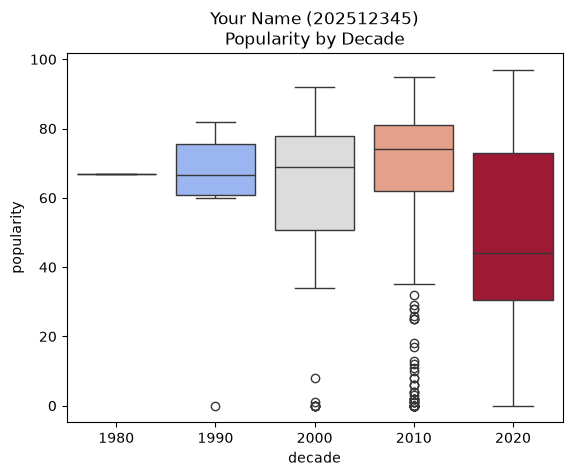

In [16]:
sns.boxplot(x='decade', y='popularity', data=df, hue='decade', palette='coolwarm', legend=False)
plt.title(T+"Popularity by Decade"); plt.show()

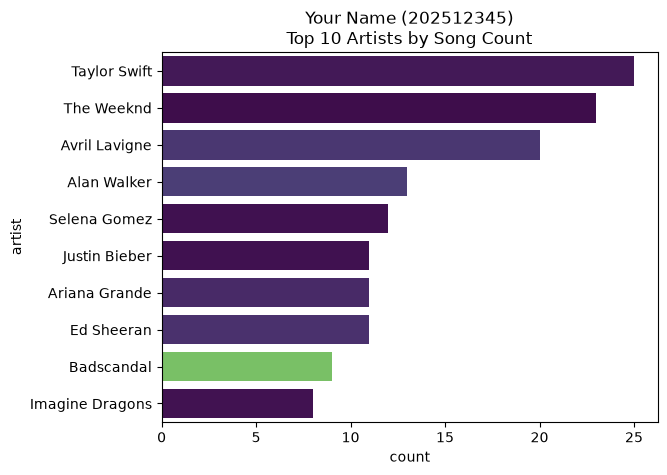

In [17]:
sns.countplot(y='artist', data=df, order=df['artist'].value_counts().head(10).index,
              hue='artist', palette='viridis', legend=False)
plt.title(T+"Top 10 Artists by Song Count"); plt.show()

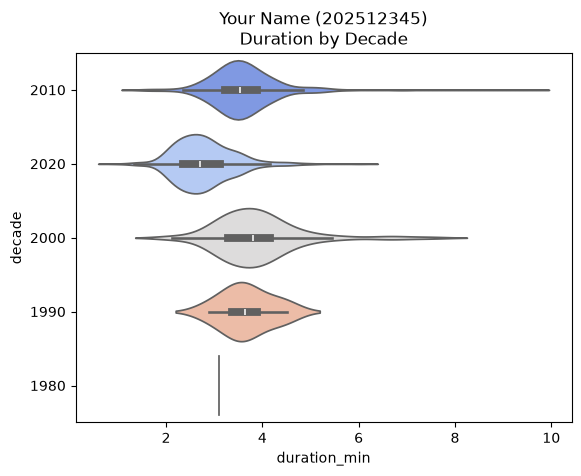

In [18]:
sns.violinplot(data=df.assign(decade=df['decade'].astype(str)), x='duration_min', y='decade',
               hue='decade', palette='coolwarm', density_norm='width', legend=False)
plt.title(T+"Duration by Decade"); plt.show()

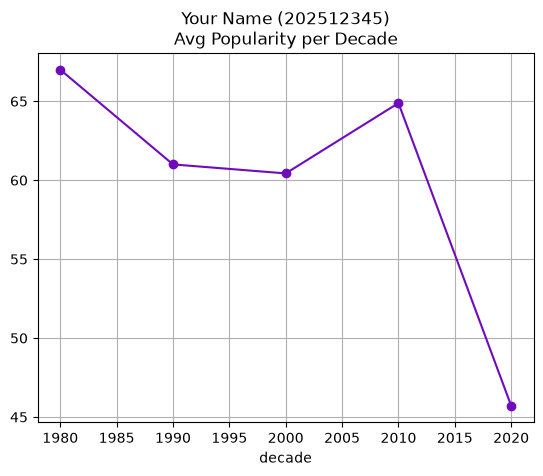

In [19]:
df.groupby('decade')['popularity'].mean().plot(kind='line', color=color1, marker='o')
plt.title(T+"Avg Popularity per Decade"); plt.grid(True); plt.show()

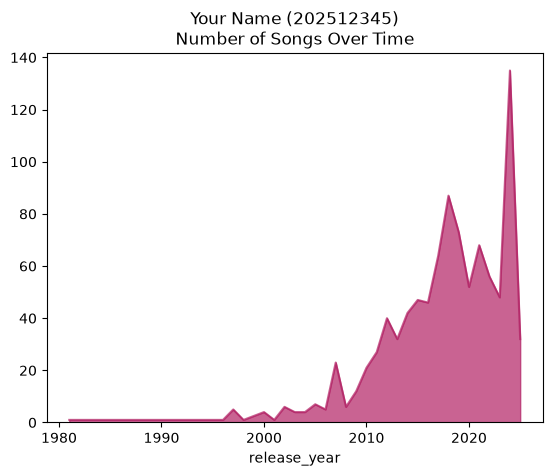

In [20]:
df['release_year'].value_counts().sort_index().plot(kind='area', color=color2, alpha=.7)
plt.title(T+"Number of Songs Over Time"); plt.show()

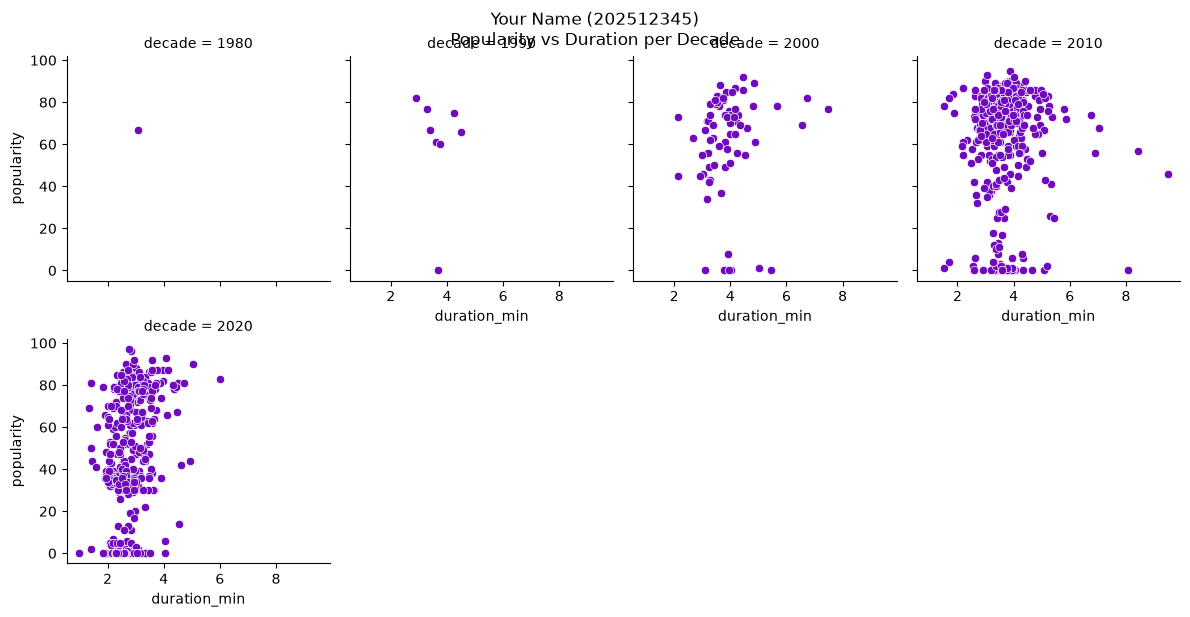

In [21]:
g = sns.FacetGrid(df, col='decade', col_wrap=4, height=3)
g.map_dataframe(sns.scatterplot, x='duration_min', y='popularity', color=color1)
g.fig.suptitle(T+"Popularity vs Duration per Decade", y=1.02); plt.show()

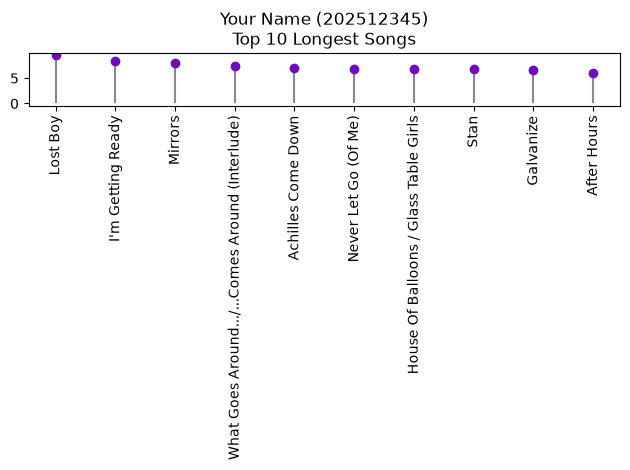

In [23]:
lg = df.nlargest(10, 'duration_min'); x = range(10)
plt.vlines(x, 0, lg['duration_min'], color='#888'); plt.plot(x, lg['duration_min'], 'o', color=color1)
plt.xticks(x, lg['track_name'], rotation=90)
plt.title(T+"Top 10 Longest Songs"); plt.tight_layout(); plt.show()

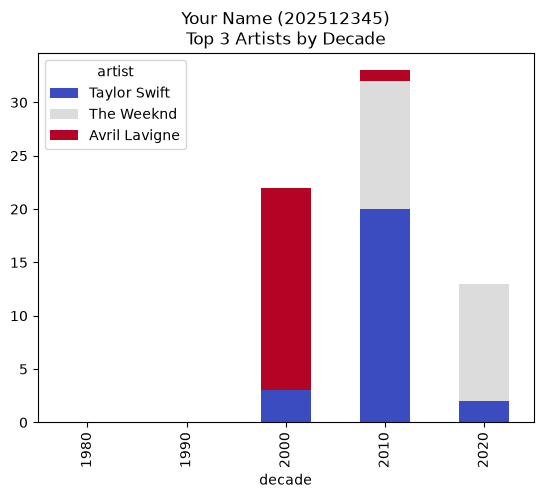

In [24]:
pd.crosstab(df['decade'], df['artist'])[top3].plot(kind='bar', stacked=True, colormap='coolwarm')
plt.title(T+"Top 3 Artists by Decade"); plt.show()

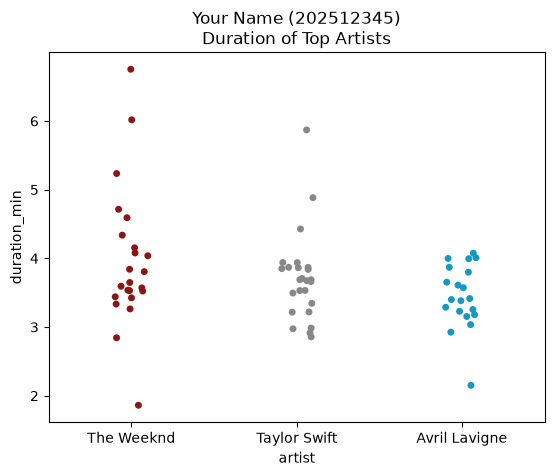

In [25]:
sns.stripplot(data=df[df['artist'].isin(top3)], x='artist', y='duration_min',
              hue='artist', palette=['#8C1515', '#888888', '#1598C1'], legend=False)
plt.title(T+"Duration of Top Artists"); plt.show()

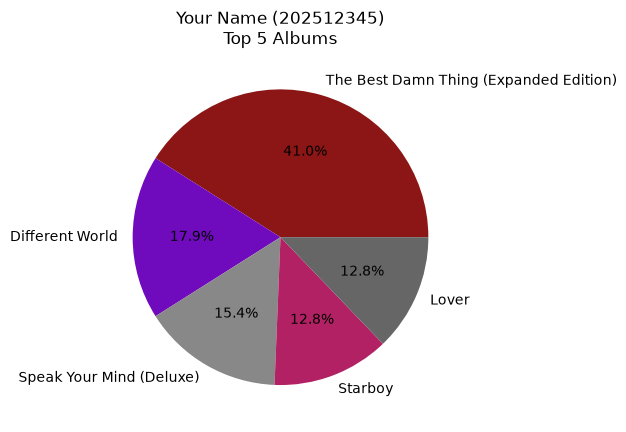

In [26]:
ta = df['album'].value_counts().head(5)
plt.pie(ta, labels=ta.index, autopct='%1.1f%%', colors=['#8C1515', color1, '#888', color2, '#666'])
plt.title(T+"Top 5 Albums"); plt.show()

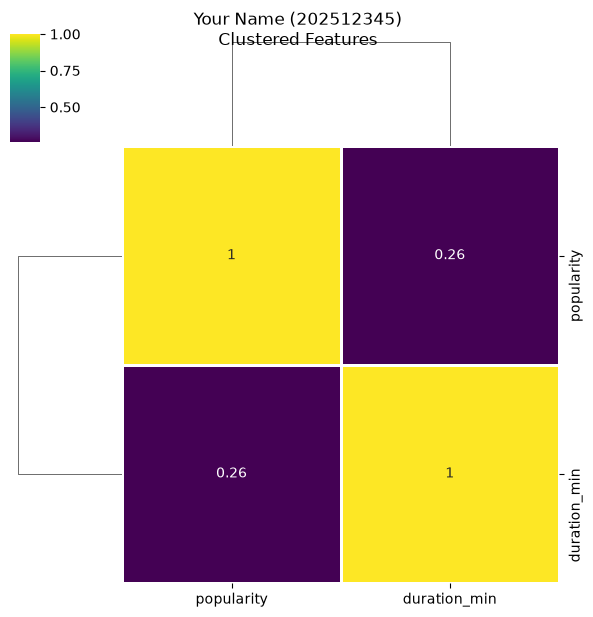

In [27]:
sns.clustermap(df[['popularity', 'duration_min']].dropna().corr(), annot=True,
               cmap='viridis', linewidths=.75, figsize=(6, 6))
plt.suptitle(T+"Clustered Features", y=1.02); plt.show()

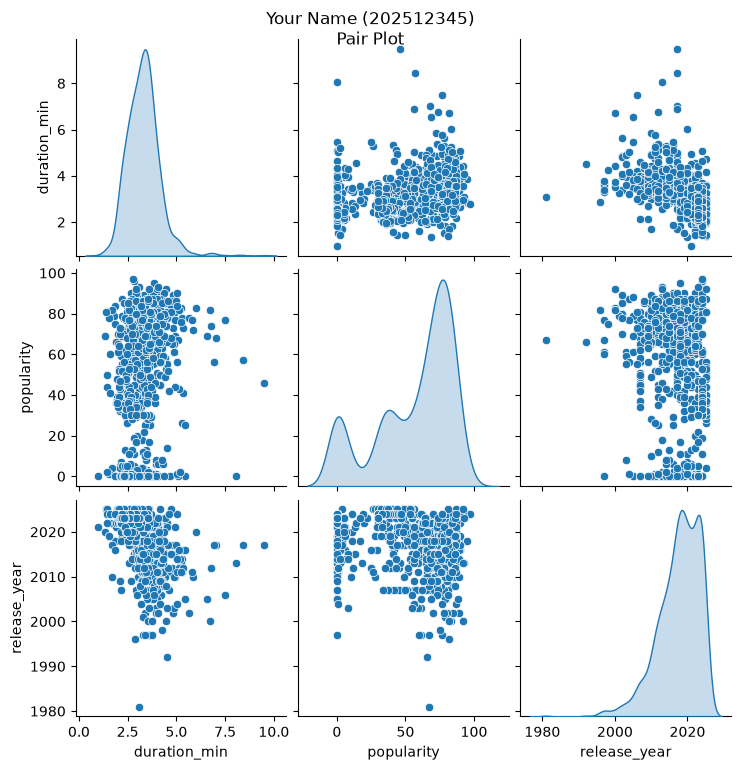

In [28]:
sns.pairplot(df[['duration_min', 'popularity', 'release_year']], diag_kind='kde')
plt.suptitle(T+"Pair Plot", y=1.02); plt.show()

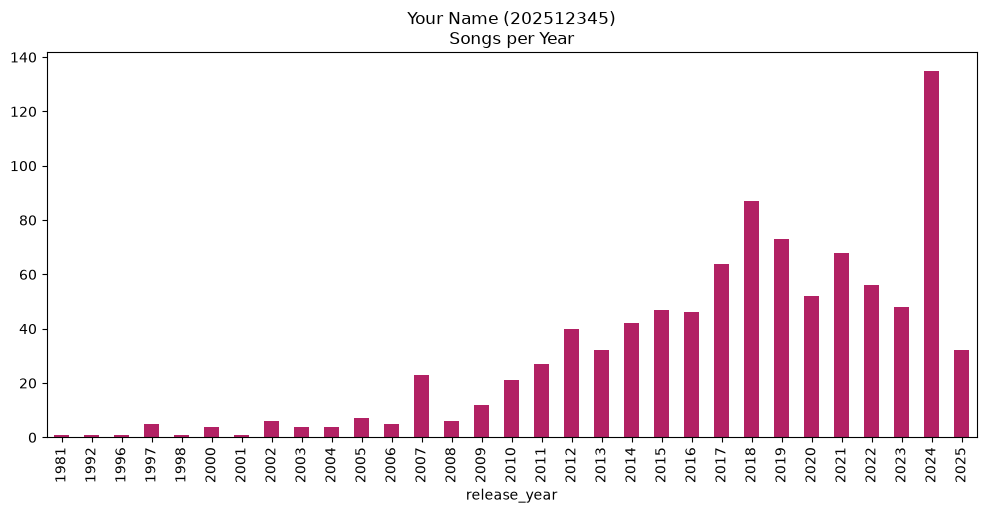

In [29]:
df['release_year'].value_counts().sort_index().plot(kind='bar', color=color2, figsize=(12, 5))
plt.title(T+"Songs per Year"); plt.show()

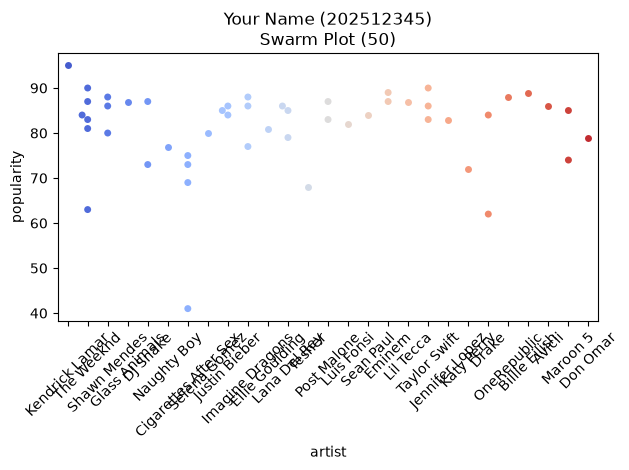

In [30]:
sns.swarmplot(data=df.head(50), x='artist', y='popularity', hue='artist', palette='coolwarm', legend=False)
plt.xticks(rotation=45); plt.title(T+"Swarm Plot (50)"); plt.tight_layout(); plt.show()

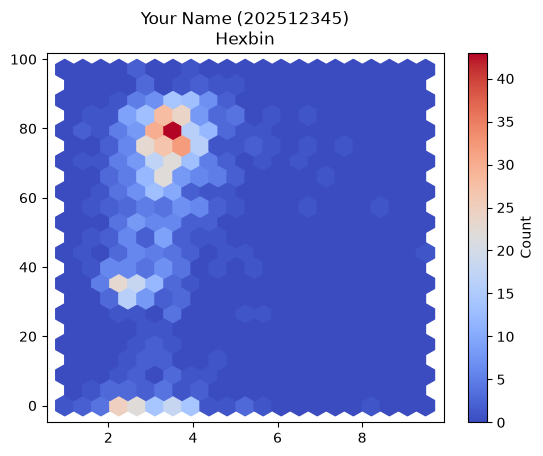

In [31]:
plt.hexbin(df['duration_min'], df['popularity'], gridsize=20, cmap='coolwarm')
plt.colorbar(label='Count'); plt.title(T+"Hexbin"); plt.show()

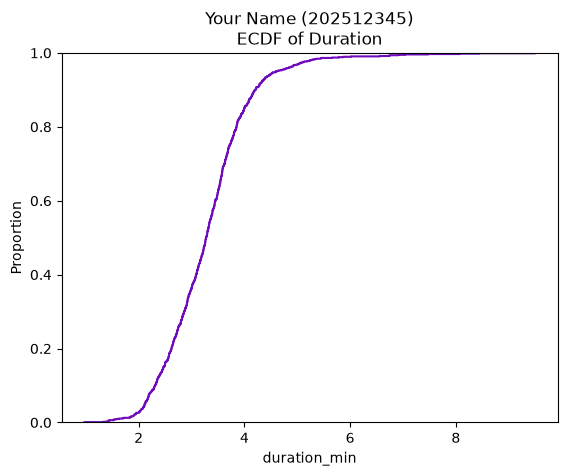

In [32]:
sns.ecdfplot(data=df, x='duration_min', color=color1)
plt.title(T+"ECDF of Duration"); plt.show()

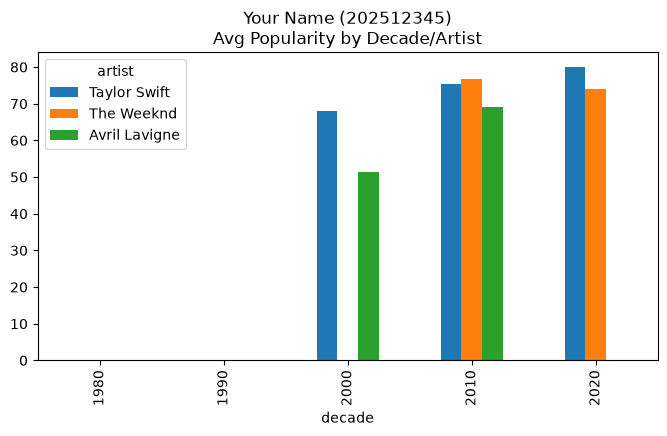

In [33]:
df.groupby(['decade', 'artist'])['popularity'].mean().unstack().fillna(0)[top3].plot(kind='bar', figsize=(8, 4))
plt.title(T+"Avg Popularity by Decade/Artist"); plt.show()

In [37]:
import os
import webbrowser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

student_name = "Jhon Mark Osorio"
student_id = "20254269"

id_num = int(student_id[-3:])
color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color_line = f"#{(id_num * 11) % 256:02x}{(id_num * 4) % 256:02x}{(id_num * 8) % 256:02x}"
cmap_color = "plasma"

Top 10 Longest Tracks:
                                        track_name                 artist  duration_min
0                                         Lost Boy                  Jaden      9.497883
1                                I'm Getting Ready    Tasha Cobbs Leonard      8.436667
2                                          Mirrors      Justin Timberlake      8.069100
3  What Goes Around.../...Comes Around (Interlude)      Justin Timberlake      7.476217
4                               Achilles Come Down         Gang of Youths      7.035767
5                             Never Let Go (Of Me)                 Baltra      6.909833
6            House Of Balloons / Glass Table Girls             The Weeknd      6.753550
7                                             Stan                 Eminem      6.735100
8                                        Galvanize  The Chemical Brothers      6.563550
9                                      After Hours             The Weeknd      6.017100


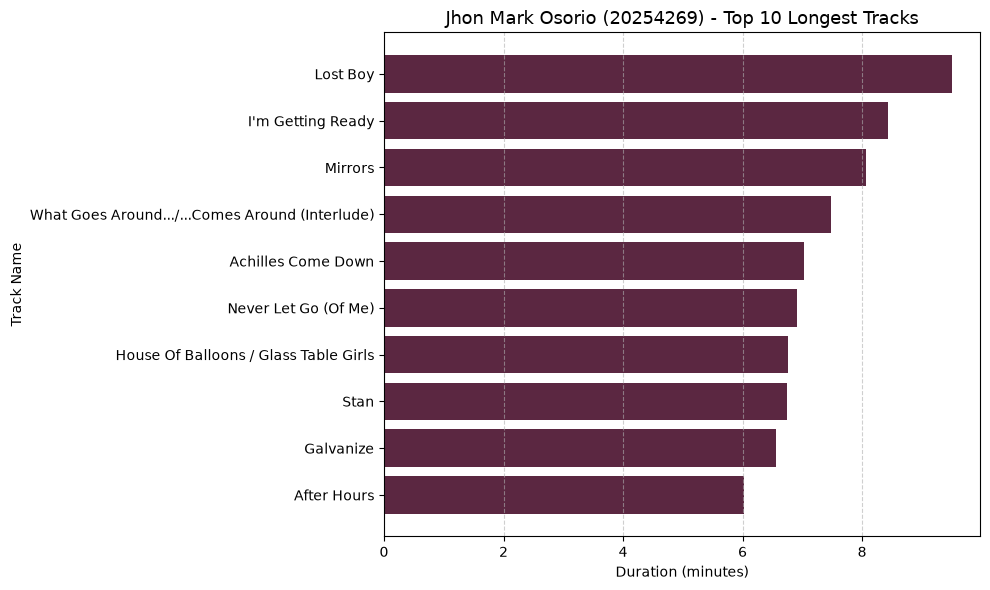

In [38]:
top10_longest = (
    df.dropna(subset=["duration_min"])
    .sort_values(by="duration_min", ascending=False)
    .head(10)[["track_name", "artist", "duration_min"]]
    .reset_index(drop=True)
)

print("Top 10 Longest Tracks:")
print(top10_longest.to_string(index=True))

plot_df = top10_longest.iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(plot_df["track_name"], plot_df["duration_min"], color=color_bar)
plt.title(f"{student_name} ({student_id}) - Top 10 Longest Tracks", fontsize=13)
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

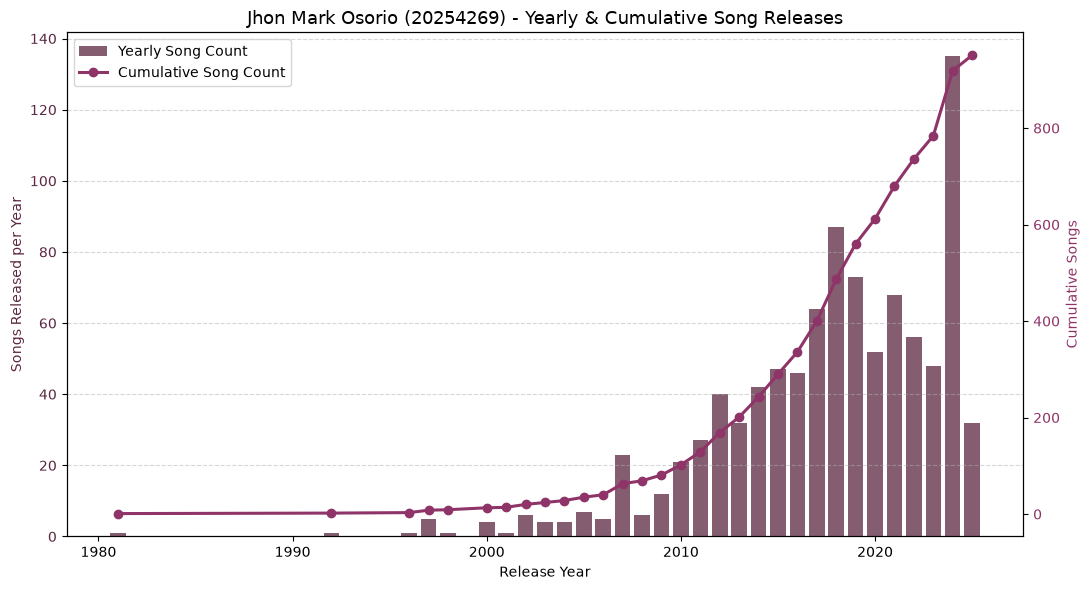

In [39]:
yearly_counts = (
    df[df["year"] > 0]
    .groupby("year")["track_name"]
    .count()
    .sort_index()
)
cumulative_counts = yearly_counts.cumsum()

fig, ax1 = plt.subplots(figsize=(11, 6))

bars = ax1.bar(
    yearly_counts.index,
    yearly_counts.values,
    color=color_bar,
    alpha=0.75,
    label="Yearly Song Count"
)
ax1.set_xlabel("Release Year")
ax1.set_ylabel("Songs Released per Year", color=color_bar)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
(line,) = ax2.plot(
    cumulative_counts.index,
    cumulative_counts.values,
    color=color_line,
    marker="o",
    linewidth=2.2,
    label="Cumulative Song Count"
)
ax2.set_ylabel("Cumulative Songs", color=color_line)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title(
    f"{student_name} ({student_id}) - Yearly & Cumulative Song Releases",
    fontsize=13
)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [41]:
hex_df = df[(df["year"] > 0)].dropna(subset=["duration_min", "popularity", "year"]).copy()
hex_df["year"] = hex_df["year"].astype(int)
years_sorted = sorted(hex_df["year"].unique())

x_min, x_max = hex_df["duration_min"].min(), hex_df["duration_min"].max()
y_min, y_max = hex_df["popularity"].min(), hex_df["popularity"].max()

fig, ax = plt.subplots(figsize=(9, 6))

def update_hexbin(yr):
    ax.clear()
    sub = hex_df[hex_df["year"] <= yr]
    hb = ax.hexbin(
        sub["duration_min"],
        sub["popularity"],
        gridsize=20,
        extent=(x_min, x_max, y_min, y_max),
        cmap=cmap_color,
        mincnt=1
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Popularity Score")
    ax.set_title(
        f"{student_name} ({student_id}) - Duration vs. Popularity Density (Up to {yr})",
        fontsize=12
    )
    return (hb,)

ani_hex = FuncAnimation(
    fig, update_hexbin, frames=years_sorted, interval=250, repeat=False
)

hex_gif_path = os.path.abspath("duration_popularity_hexbin_evolution.gif")
ani_hex.save(hex_gif_path, writer=PillowWriter(fps=4))
print(f"Animated hexbin GIF saved at: {hex_gif_path}")
webbrowser.open(f"file://{hex_gif_path}")
plt.close(fig)

Animated hexbin GIF saved at: c:\Users\jhonm\OneDrive\Desktop\ComProg1\Lab8_Data_Visualization_Osorio\duration_popularity_hexbin_evolution.gif
